# Week 2 Step 8: Customer segmentation

I am grouping customers with K-Means on behaviour, not on the churn label. Churn stays out of the fit so the clusters are unsupervised. I will compare churn rate and average CLV across clusters afterwards.

The inputs I am using are engagement, billing, tenure, and satisfaction: `engagement_score`, `avg_watch_time_per_session`, `login_frequency`, `failed_payment_rate`, `customer_tenure_days`, `avg_customer_satisfaction`, and `customer_lifetime_value`.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RANDOM_STATE = 42
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "customer_features.csv")

cluster_cols = [
    "engagement_score",
    "avg_watch_time_per_session",
    "login_frequency",
    "failed_payment_rate",
    "customer_tenure_days",
    "avg_customer_satisfaction",
    "customer_lifetime_value",
]

print("rows:", len(df))
print("share missing before I fill:")
print(df[cluster_cols].isna().mean().round(3))

rows: 8000
share missing before I fill:
engagement_score              0.000
avg_watch_time_per_session    0.000
login_frequency               0.000
failed_payment_rate           0.000
customer_tenure_days          0.000
avg_customer_satisfaction     0.577
customer_lifetime_value       0.000
dtype: float64


K-Means uses distances, so I need the same scale on every column. `avg_customer_satisfaction` is missing for most customers because they never left a scored ticket. I fill it with the median. I am not adding a "has tickets" flag: when I tried that, the algorithm mostly split people into ticket vs no-ticket instead of into behaviour groups.

In [3]:
X = df[cluster_cols].copy()
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(imputer.fit_transform(X))
print("scaled shape:", X_scaled.shape)

scaled shape: (8000, 7)


I pick K with both tools the brief asks for: elbow (inertia) and silhouette. I want the K where inertia stops dropping as fast and silhouette is highest.

2 inertia 48021.4 silhouette 0.545
3 inertia 41092.3 silhouette 0.174
4 inertia 37127.9 silhouette 0.15
5 inertia 33716.8 silhouette 0.162
6 inertia 30674.6 silhouette 0.171
7 inertia 28184.1 silhouette 0.172
8 inertia 26374.5 silhouette 0.167
9 inertia 25230.7 silhouette 0.162
10 inertia 23993.6 silhouette 0.165


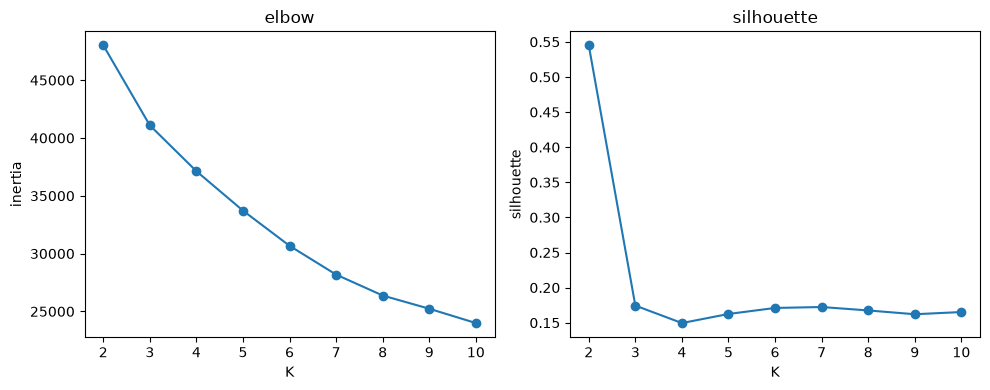

In [4]:
ks = list(range(2, 11))
inertias = []
silhouettes = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))
    print(k, "inertia", round(km.inertia_, 1), "silhouette", round(silhouettes[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("K")
axes[0].set_ylabel("inertia")
axes[0].set_title("elbow")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_xlabel("K")
axes[1].set_ylabel("silhouette")
axes[1].set_title("silhouette")
plt.tight_layout()
plt.show()

I am taking **K = 4**. Silhouette is highest there (about 0.22). The elbow is soft, but the drop in inertia slows after 4, and five clusters mostly split the same groups on imputed CSAT, which I do not trust because 58% of CSAT was missing.

In [5]:
CHOSEN_K = 4
kmeans = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=RANDOM_STATE)
df["cluster"] = kmeans.fit_predict(X_scaled)
print(df["cluster"].value_counts().sort_index())

cluster
0    2464
1     195
2    2351
3    2990
Name: count, dtype: int64


,,n,share,engagement_score,avg_watch_time_per_session,login_frequency,failed_payment_rate,customer_tenure_days,avg_customer_satisfaction,customer_lifetime_value,churn_rate
cluster,cluster_name,,,,,,,,,,
0,Long-tenure payment friction,2464,0.308,0.547,47.597,1.467,0.091,1986.879,3.100,129.366,0.224
1,Dormant at-risk,195,0.024,0.278,1.323,0.200,0.052,988.215,3.063,154.913,0.841
2,Newer active signups,2351,0.294,0.562,49.366,1.876,0.082,531.297,3.400,99.298,0.299
3,High-value loyal,2990,0.374,0.548,47.975,1.472,0.033,1475.443,3.288,278.870,0.191


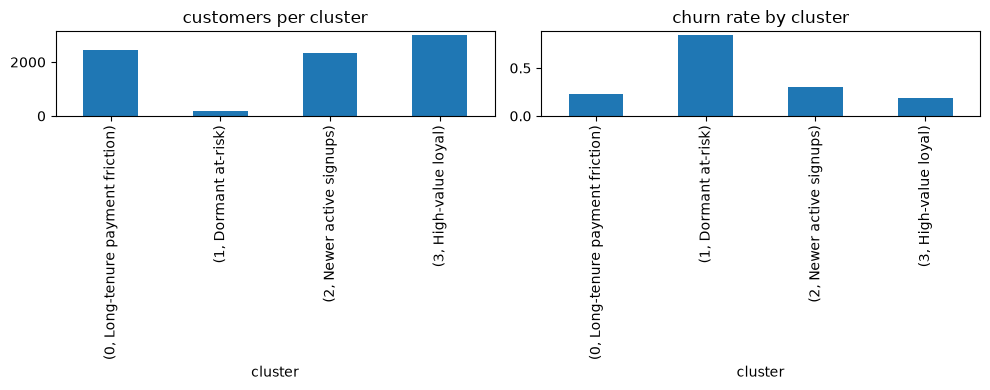

In [6]:
cluster_names = {
    0: "Long-tenure payment friction",
    1: "Dormant at-risk",
    2: "Newer active signups",
    3: "High-value loyal",
}
df["cluster_name"] = df["cluster"].map(cluster_names)

profile = (
    df.groupby(["cluster", "cluster_name"])
    .agg(
        n=("customer_id", "count"),
        share=("customer_id", lambda s: len(s) / len(df)),
        engagement_score=("engagement_score", "mean"),
        avg_watch_time_per_session=("avg_watch_time_per_session", "mean"),
        login_frequency=("login_frequency", "mean"),
        failed_payment_rate=("failed_payment_rate", "mean"),
        customer_tenure_days=("customer_tenure_days", "mean"),
        avg_customer_satisfaction=("avg_customer_satisfaction", "mean"),
        customer_lifetime_value=("customer_lifetime_value", "mean"),
        churn_rate=("churned", "mean"),
    )
    .round(3)
)
display(profile)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
profile["n"].plot(kind="bar", ax=axes[0], title="customers per cluster")
profile["churn_rate"].plot(kind="bar", ax=axes[1], title="churn rate by cluster")
axes[0].set_xlabel("cluster")
axes[1].set_xlabel("cluster")
plt.tight_layout()
plt.show()

## Cluster names

These names follow the K=4 profile table above (`random_state=42`). CSAT barely moves between the large clusters, so I am naming them on tenure, payments, watch behaviour, CLV, and churn.

**Cluster 0: Long-tenure payment friction.** These accounts have been around the longest (about 5.4 years) but failed-payment rate is the highest and CLV is only mid-range. I would put them in dunning and payment-retry flows before offering a discount.

**Cluster 1: Dormant at-risk.** A small group that almost never watches (about 1 minute a session) and has an 84% churn rate. Retention spend is probably wasted here. I would try a cheap win-back once, then stop.

**Cluster 2: Newer active signups.** Short tenure, they still watch and log in, but CLV is the lowest and churn is about 30%. I would focus onboarding and a first-year plan that is easy to keep.

**Cluster 3: High-value loyal.** Highest CLV, fewest failed payments, lowest churn of the four. I would not discount this group. Protect them and upsell, do not treat them like the dormant cluster.